# 03 — Auditoría Visual de Alertas Reales, Contrato Dashboard y Validación Oficial (`anomalias.csv`)

Validamos los artefactos finales antes de poblar **Databricks Unity Catalog (`dat_hack_rb06.rbe.*`)**:
1. Ensamblamos las tablas del contrato con `score` calibrado monótonamente en `[0.50, 0.9999]` (para el slider de `FilterBar.jsx`), `exclusion_reason` granular (`DetectorPanel.jsx`) y textos limpios en español.
2. Inspeccionamos casos reales conocidos (`R057 sala`, `R220 domicilio`, `R035 sala`, `R031 domicilio`).
3. Auditamos el **Top-25 de mayor score** (`precision@100`) y **20 alertas en la frontera del umbral**.
4. Exportamos `outputs/anomalias.csv` (con `recomendacion`) y pasamos `validar_entrega.py`.


In [10]:
import json, subprocess, sys, uuid
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "databricks" / "src" / "config.py").is_file())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from databricks.src.config import get_data_dir, get_outputs_dir
from databricks.src.scoring import build_gold_outputs, export_anomalias_csv

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 120

out_dir = get_outputs_dir()
gold_paths = {
    "model_runs": out_dir / "gold_model_runs.parquet",
    "restaurants_dim": out_dir / "gold_restaurants_dim.parquet",
    "series_summary": out_dir / "gold_series_summary.parquet",
    "alerts_prioritized": out_dir / "gold_alerts_prioritized.parquet",
}
REBUILD_GOLD = False

if not REBUILD_GOLD and all(p.is_file() for p in gold_paths.values()):
    gold = {k: pd.read_parquet(p) for k, p in gold_paths.items()}
    print("Cargados artefactos Gold ya ensamblados (preservando caché LLM Top-100 y episodios consolidados).")
else:
    df_feat = pd.read_parquet(out_dir / "silver_features.parquet")
    dim = pd.read_parquet(out_dir / "restaurants_dim.parquet")
    champ_alerts = pd.read_parquet(out_dir / "champion_alerts.parquet")
    meta = json.loads((out_dir / "champion_metrics.json").read_text(encoding="utf-8"))
    run_id = f"run_rb06_{uuid.uuid4().hex[:8]}"
    params_exec = {
        "modelo": meta["champion_name"],
        "umbral_raw": round(float(meta["threshold"]), 4),
        "bloques_oof": 6,
        "purge_dias": 14,
        "cobertura_cqr_objetivo": 0.90,
        "f1_oos": meta["metrics"]["f1"],
        "precision_at_100_oos": meta["metrics"]["precision_at_100"],
        "recall_impacto_eur_oos": meta["metrics"]["recall_impact_eur"],
        **(meta.get("extra_params") or {}),
    }
    gold = build_gold_outputs(
        df_features=df_feat,
        restaurants_dim=dim,
        pred_alerts=champ_alerts,
        run_id=run_id,
        model_version=meta["model_version"],
        synthetic_metrics=meta["metrics"],
        params_dict=params_exec,
    )

alerts = gold["alerts_prioritized"].sort_values("score", ascending=False, kind="mergesort").reset_index(drop=True)
run_row = gold["model_runs"].iloc[0]
print("Resumen Gold:")
print(f"  - model_runs         : {len(gold['model_runs'])} fila ({run_row['model_version']}, run_id={run_row['run_id']})")
print(f"  - restaurants_dim    : {len(gold['restaurants_dim'])} filas")
print(f"  - series_summary     : {len(gold['series_summary']):,} filas (is_anomaly=True: {int(gold['series_summary']['is_anomaly'].sum()):,})")
print(f"  - alerts_prioritized : {len(alerts):,} filas | Episodios consolidados: {alerts['episode_id'].nunique():,} | llm_cached: {int(alerts['llm_cached'].sum())}")
print(f"  - Rango score [0..1] : {alerts['score'].min():.4f} .. {alerts['score'].max():.6f}")
print("  - Niveles de prioridad:", alerts["prioridad_nivel"].value_counts().to_dict())


Cargados artefactos Gold ya ensamblados (preservando caché LLM Top-100 y episodios consolidados).
Resumen Gold:
  - model_runs         : 1 fila (v3_ensemble_cqr_ctx, run_id=run_rb06_3cef028f)
  - restaurants_dim    : 541 filas
  - series_summary     : 1,377,194 filas (is_anomaly=True: 3,367)
  - alerts_prioritized : 3,367 filas | Episodios consolidados: 2,441 | llm_cached: 100
  - Rango score [0..1] : 0.5000 .. 0.999900
  - Niveles de prioridad: {'P2': 2629, 'P1': 721, 'P3': 17}


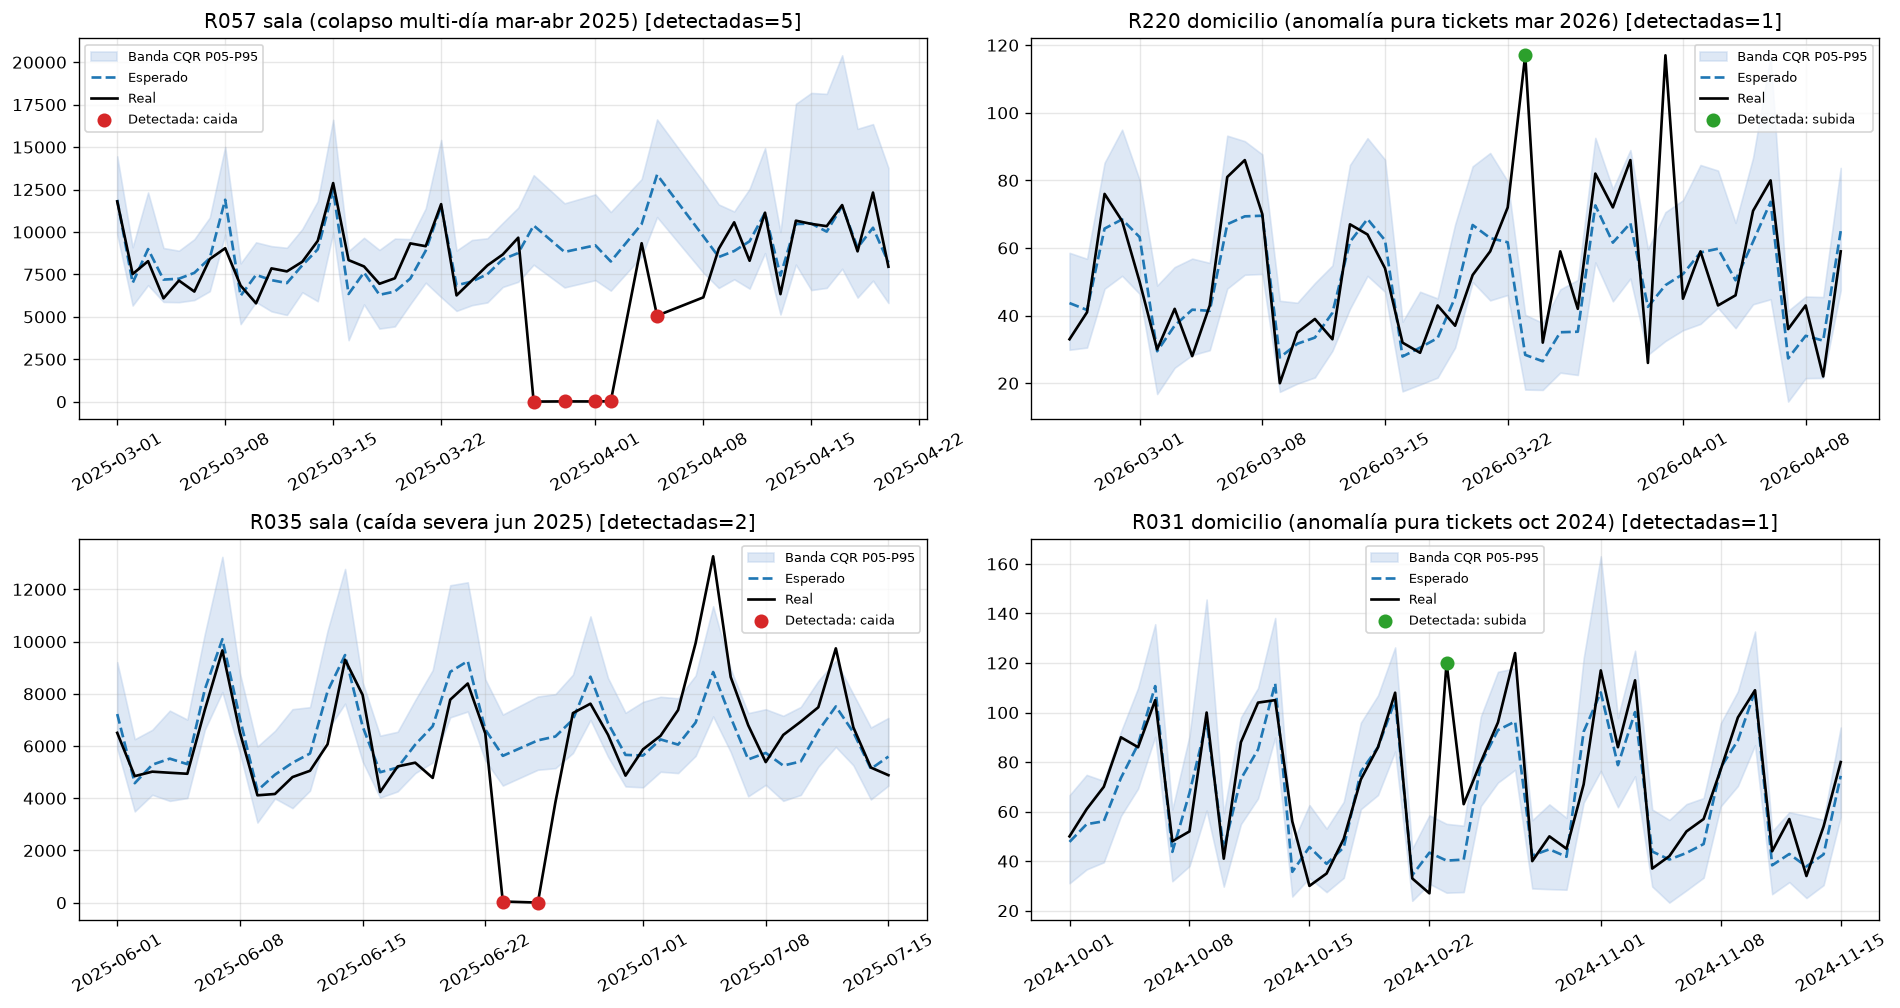

In [11]:
# Verificación visual de 4 casos reales conocidos (real vs esperado + bandas CQR P05-P95)
cases = [
    ("R057", "sala", "2025-03-01", "2025-04-20", "ventas", "R057 sala (colapso multi-día mar-abr 2025)"),
    ("R220", "domicilio", "2026-02-25", "2026-04-10", "tickets", "R220 domicilio (anomalía pura tickets mar 2026)"),
    ("R035", "sala", "2025-06-01", "2025-07-15", "ventas", "R035 sala (caída severa jun 2025)"),
    ("R031", "domicilio", "2024-10-01", "2024-11-15", "tickets", "R031 domicilio (anomalía pura tickets oct 2024)"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 8.5))
ss = gold["series_summary"].copy()
ss["fecha_dt"] = pd.to_datetime(ss["fecha"])

for ax, (rid, canal, d0, d1, metric, title) in zip(axes.flat, cases):
    sub = ss[(ss["restaurante_id"] == rid) & (ss["canal"] == canal) & (ss["fecha_dt"].between(d0, d1))].sort_values("fecha_dt")
    exp_col = "ventas_esperadas" if metric == "ventas" else "tickets_esperados"
    p05_col = "ventas_p05" if metric == "ventas" else "tickets_p05"
    p95_col = "ventas_p95" if metric == "ventas" else "tickets_p95"

    ax.fill_between(sub["fecha_dt"], sub[p05_col], sub[p95_col], color="#aec7e8", alpha=0.4, label="Banda CQR P05-P95")
    ax.plot(sub["fecha_dt"], sub[exp_col], color="#1f77b4", ls="--", lw=1.6, label="Esperado")
    ax.plot(sub["fecha_dt"], sub[metric], color="black", lw=1.6, label="Real")

    an = sub[sub["is_anomaly"]]
    for tipo_v, col_m in [("caida", "#d62728"), ("subida", "#2ca02c")]:
        ant = an[an["anomaly_tipo"] == tipo_v]
        if not ant.empty:
            ax.scatter(ant["fecha_dt"], ant[metric], color=col_m, s=55, zorder=5, label=f"Detectada: {tipo_v}")

    ax.set_title(f"{title} [detectadas={len(an)}]")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


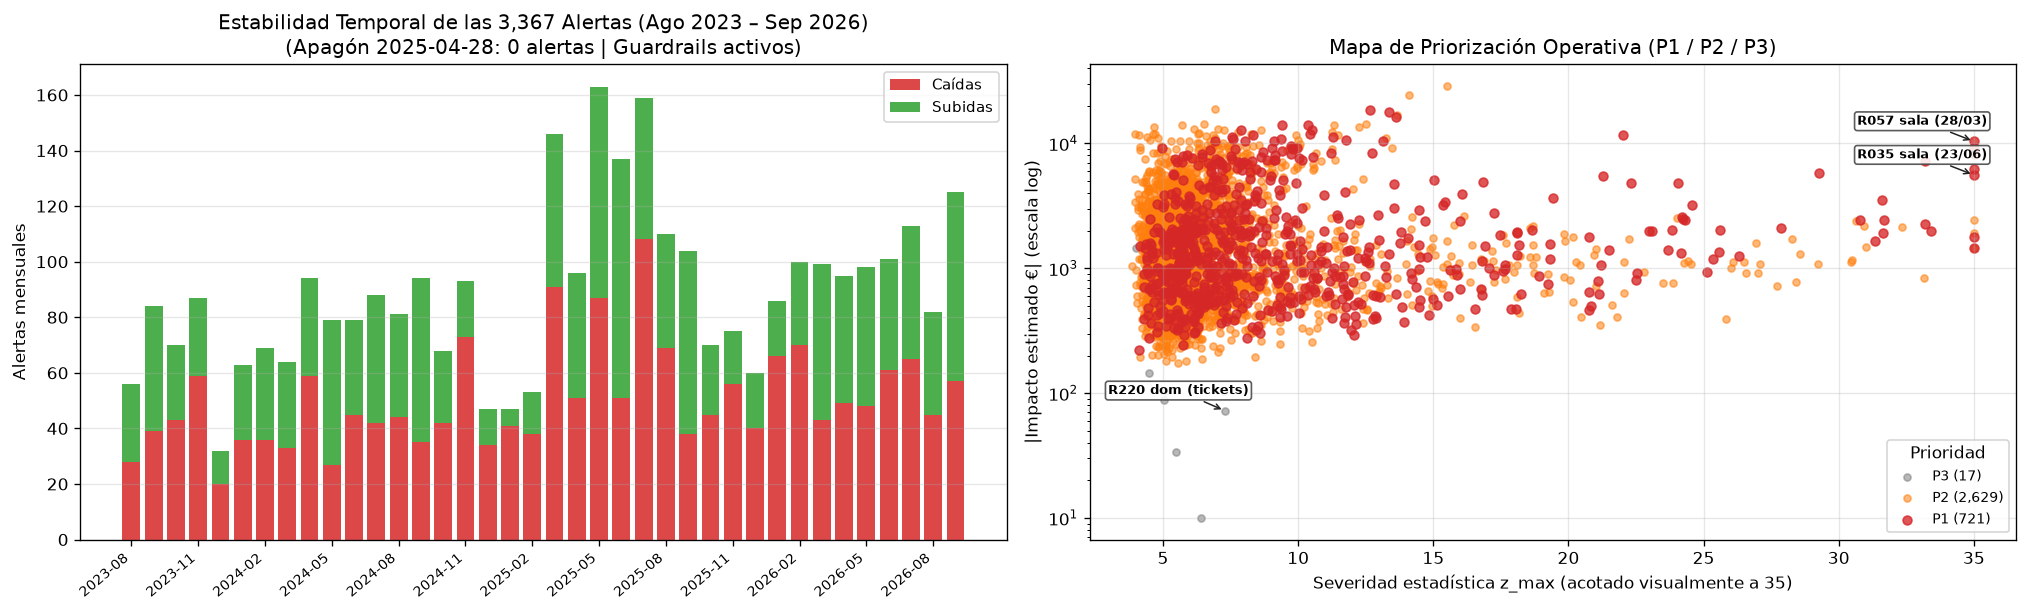

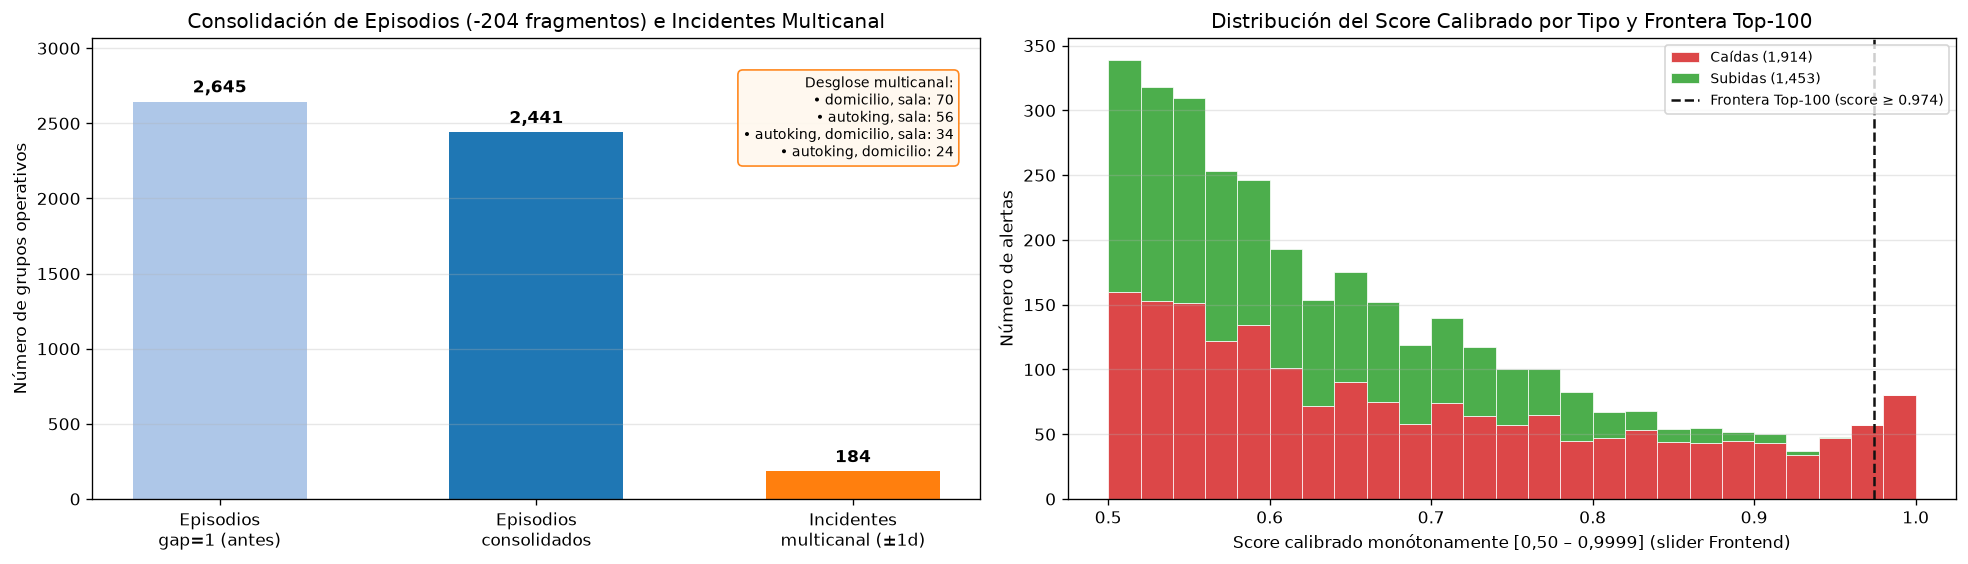

In [12]:
# Gráficos de Negocio, Estabilidad Temporal, Priorización P1/P2/P3 y Episodios Consolidados + Multicanal
fig_dir = REPO_ROOT / "docs" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

a_plot = alerts.copy()
a_plot["fecha_dt"] = pd.to_datetime(a_plot["fecha"])
a_plot["mes"] = a_plot["fecha_dt"].dt.to_period("M").astype(str)
a_plot["impacto_abs"] = a_plot["impacto_estimado_eur"].abs()

# 1) Serie temporal mensual + Mapa de priorización operativa (|Impacto EUR| vs z_max)
fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))

monthly = a_plot.groupby(["mes", "tipo"]).size().unstack(fill_value=0).sort_index()
x_m = np.arange(len(monthly))
axes[0].bar(x_m, monthly.get("caida", 0), label="Caídas", color="#d62728", alpha=0.85)
axes[0].bar(x_m, monthly.get("subida", 0), bottom=monthly.get("caida", 0), label="Subidas", color="#2ca02c", alpha=0.85)
tick_step = max(1, len(monthly) // 10)
axes[0].set_xticks(x_m[::tick_step])
axes[0].set_xticklabels(monthly.index[::tick_step], rotation=40, ha="right", fontsize=8.5)
axes[0].set_ylabel("Alertas mensuales")
axes[0].set_title(f"Estabilidad Temporal de las {len(a_plot):,} Alertas (Ago 2023 – Sep 2026)\n(Apagón 2025-04-28: 0 alertas | Guardrails activos)")
axes[0].legend(fontsize=9)
axes[0].grid(axis="y", alpha=0.3)

prio_colors = {"P1": "#d62728", "P2": "#ff7f0e", "P3": "#7f7f7f"}
for pr in ["P3", "P2", "P1"]:
    sub_p = a_plot[a_plot["prioridad_nivel"] == pr]
    axes[1].scatter(
        sub_p["z_max"].clip(upper=35),
        sub_p["impacto_abs"].clip(lower=10),
        c=prio_colors[pr],
        alpha=0.55 if pr != "P1" else 0.78,
        s=18 if pr != "P1" else 28,
        label=f"{pr} ({len(sub_p):,})",
    )
axes[1].set_yscale("log")
axes[1].set_xlabel("Severidad estadística z_max (acotado visualmente a 35)")
axes[1].set_ylabel("|Impacto estimado €| (escala log)")
axes[1].set_title("Mapa de Priorización Operativa (P1 / P2 / P3)")
# Anotar casos destacados
for rid_a, f_a, lbl_a in [
    ("R057", "2025-03-28", "R057 sala (28/03)"),
    ("R220", "2026-03-23", "R220 dom (tickets)"),
    ("R035", "2025-06-23", "R035 sala (23/06)"),
]:
    hit = a_plot[(a_plot["restaurante_id"] == rid_a) & (a_plot["fecha"].astype(str) == f_a)]
    if not hit.empty:
        r0 = hit.iloc[0]
        axes[1].annotate(
            lbl_a,
            xy=(min(float(r0["z_max"]), 35.0), max(float(r0["impacto_abs"]), 10.0)),
            xytext=(-70, 10),
            textcoords="offset points",
            fontsize=8,
            fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="#222222", lw=0.9),
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#444444", alpha=0.88),
        )
axes[1].legend(title="Prioridad", fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "03_negocio_temporal_y_priorizacion.png", dpi=180, bbox_inches="tight")
plt.show()

# 2) Consolidación de episodios + incidentes multicanal + descomposición de métrica por canal
fig, axes = plt.subplots(1, 2, figsize=(16.5, 4.8))

ev_parsed = [json.loads(x) for x in a_plot["evidencia_json"]]
a_plot["incident_id"] = [e.get("incident_id", "") for e in ev_parsed]
a_plot["incident_canales"] = [", ".join(e.get("incident_canales", [])) for e in ev_parsed]
a_plot["incident_multicanal"] = [bool(e.get("incident_multicanal", False)) for e in ev_parsed]

inc_multi = (
    a_plot[a_plot["incident_multicanal"]]
    .drop_duplicates("incident_id")["incident_canales"]
    .value_counts()
)
# Comparativa de fragmentación: gap==1 vs consolidado (<=3d + puente)
a_sorted = a_plot.sort_values(["restaurante_id", "canal", "tipo", "fecha_dt"]).reset_index(drop=True)
prev_dt = a_sorted.groupby(["restaurante_id", "canal", "tipo"])["fecha_dt"].shift(1)
same_k = (
    (a_sorted["restaurante_id"] == a_sorted["restaurante_id"].shift(1))
    & (a_sorted["canal"] == a_sorted["canal"].shift(1))
    & (a_sorted["tipo"] == a_sorted["tipo"].shift(1))
)
ep_gap1 = int((~(same_k & ((a_sorted["fecha_dt"] - prev_dt).dt.days == 1))).sum())
ep_cons = int(a_plot["episode_id"].nunique())
n_inc_multi = int(a_plot[a_plot["incident_multicanal"]]["incident_id"].nunique())

labels_inc = [f"Episodios\ngap=1 (antes)", f"Episodios\nconsolidados", "Incidentes\nmulticanal (±1d)"]
vals_inc = [ep_gap1, ep_cons, n_inc_multi]
cols_inc = ["#aec7e8", "#1f77b4", "#ff7f0e"]
bars_i = axes[0].bar(labels_inc, vals_inc, color=cols_inc, width=0.55)
for b_i, v_i in zip(bars_i, vals_inc):
    axes[0].text(b_i.get_x() + b_i.get_width() / 2, v_i + 35, f"{v_i:,}", ha="center", va="bottom", fontweight="bold", fontsize=10)
combo_txt = "\n".join([f"• {k}: {v}" for k, v in inc_multi.items()])
axes[0].text(0.97, 0.92, f"Desglose multicanal:\n{combo_txt}", transform=axes[0].transAxes,
             ha="right", va="top", fontsize=8.5,
             bbox=dict(boxstyle="round,pad=0.35", fc="#fff8ee", ec="#ff7f0e", alpha=0.92))
axes[0].set_ylim(0, max(vals_inc) * 1.16)
axes[0].set_ylabel("Número de grupos operativos")
axes[0].set_title(f"Consolidación de Episodios (-{ep_gap1 - ep_cons} fragmentos) e Incidentes Multicanal")
axes[0].grid(axis="y", alpha=0.3)

# Panel B: Distribución del score calibrado [0.50, 0.9999] por dirección + frontera Top-100
bins_s = np.linspace(0.50, 1.00, 26)
sc_caida = a_plot.loc[a_plot["tipo"] == "caida", "score"].to_numpy()
sc_subida = a_plot.loc[a_plot["tipo"] == "subida", "score"].to_numpy()
top100_cut = float(a_plot.iloc[min(99, len(a_plot) - 1)]["score"])
axes[1].hist([sc_caida, sc_subida], bins=bins_s, stacked=True, label=[f"Caídas ({len(sc_caida):,})", f"Subidas ({len(sc_subida):,})"],
             color=["#d62728", "#2ca02c"], alpha=0.85, edgecolor="white", linewidth=0.5)
axes[1].axvline(top100_cut, color="#111111", ls="--", lw=1.5, label=f"Frontera Top-100 (score ≥ {top100_cut:.3f})")
axes[1].set_xlabel("Score calibrado monótonamente [0,50 – 0,9999] (slider Frontend)")
axes[1].set_ylabel("Número de alertas")
axes[1].set_title("Distribución del Score Calibrado por Tipo y Frontera Top-100")
axes[1].legend(loc="upper right", fontsize=8.5)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(fig_dir / "03_episodios_multicanal_y_descomposicion.png", dpi=180, bbox_inches="tight")
plt.show()


In [13]:
# Auditoría humana: Top-25 alertas (precision@100) y 20 alertas en la frontera del umbral
cols_show = [
    "restaurante_id", "canal", "fecha", "tipo", "score", "priority_score", "prioridad_nivel",
    "ventas_reales", "ventas_esperadas", "tickets_reales", "tickets_esperados",
    "impacto_estimado_eur", "otros_canales_normales", "explicacion_negocio"
]
print("=== TOP 25 ALERTAS POR SCORE ===")
display(alerts[cols_show].head(25))

print("\n=== 20 ALERTAS EN LA FRONTERA DEL UMBRAL (MENOR SCORE) ===")
display(alerts[cols_show].tail(20))


=== TOP 25 ALERTAS POR SCORE ===


,restaurante_id,canal,fecha,tipo,score,priority_score,prioridad_nivel,ventas_reales,ventas_esperadas,tickets_reales,tickets_esperados,impacto_estimado_eur,otros_canales_normales,explicacion_negocio
0,R057,sala,2025-03-28,caida,0.999900,95.28,P1,7.50,10380.84,1,953.55,-10373.34,False,"La sala registró 1 ticket y 7,50 € de ventas frente a los 953,55 tickets y 10.380,84 € esperados, lo que supone un i..."
1,R057,sala,2025-03-30,caida,0.999898,95.28,P1,17.67,8822.70,1,756.32,-8805.03,False,"Las ventas de sala fueron de 17,67 € frente a 8.822,70 € esperados (-99,8 %), con 1 ticket real frente a 756,3 esper..."
2,R057,sala,2025-04-02,caida,0.999895,95.28,P1,26.85,8262.75,2,757.64,-8235.90,False,"Las ventas reales fueron de 26,85 € frente a 8.262,75 € esperados (-99,68 %), con 2 tickets frente a 757,64 esperado..."
3,R057,sala,2025-04-01,caida,0.999890,95.28,P1,14.91,9213.80,4,836.97,-9198.89,False,"El 1 de abril de 2025 la sala facturó 14,91 € frente a los 9.213,8 € esperados (-99,84 %), con 4 tickets reales fren..."
4,R035,sala,2025-06-25,caida,0.999879,87.16,P1,4.22,6217.15,1,712.67,-6212.93,False,"El restaurante R035 registró el 25/06/2025 en sala 4,22 € de ventas frente a 6.217,15 € esperados (impacto de -6.212..."
5,R035,sala,2025-06-23,caida,0.999852,87.16,P1,44.65,5624.27,2,644.87,-5579.62,False,"En sala, el 23/06/2025 se registraron 44,65 € de ventas reales frente a 5.624,27 € esperados (desviación del -99,21 ..."
6,R541,sala,2026-05-30,caida,0.999612,74.55,P2,10.11,2438.32,1,191.03,-2428.21,False,"El restaurante R541 registró en sala el 30/05/2026 ventas de 10,11 € frente a 2.438,32 € esperados (desviación del -..."
7,R123,sala,2025-02-19,caida,0.999530,72.11,P2,20.31,1479.84,3,169.40,-1459.53,False,"El canal sala del restaurante R123 facturó 20,31 € frente a los 1.479,84 € esperados (-98,63 %), con 3 tickets frent..."
8,R422,sala,2023-12-11,caida,0.999268,78.85,P1,4.32,1459.33,1,129.74,-1455.01,False,"En sala, el local registró 4,32 € de ventas reales frente a 1.459,33 € esperados, con 1 ticket real frente a 129,74 ..."
9,R415,sala,2024-04-08,caida,0.999039,81.31,P1,39.40,1815.87,1,173.06,-1776.47,False,"El restaurante R415 registró en sala el 08/04/2024 ventas de 39,4 € frente a 1.815,87 € esperados, con un impacto de..."



=== 20 ALERTAS EN LA FRONTERA DEL UMBRAL (MENOR SCORE) ===


,restaurante_id,canal,fecha,tipo,score,priority_score,prioridad_nivel,ventas_reales,ventas_esperadas,tickets_reales,tickets_esperados,impacto_estimado_eur,otros_canales_normales,explicacion_negocio
3347,R449,sala,2026-04-17,subida,0.500712,54.98,P2,6111.19,2942.18,394,243.62,3169.01,True,"Sala: subida atípica de ventas (6.111 € frente a 2.942 € esperados, +107,7 %; impacto +3.169 €) y 394 tickets (+61,7..."
3348,R345,sala,2025-11-26,caida,0.500619,83.77,P1,492.63,933.54,54,84.16,-440.91,True,"Sala: caída atípica de ventas (493 € frente a 934 € esperados, -47,2 %; impacto -441 €) y 54 tickets (-35,8 %). Los ..."
3349,R233,sala,2026-03-03,subida,0.500613,52.76,P2,4036.21,2282.44,321,210.47,1753.77,True,"Sala: subida atípica de ventas (4.036 € frente a 2.282 € esperados, +76,8 %; impacto +1.754 €) y 321 tickets (+52,5 ..."
3350,R022,autoking,2024-01-26,caida,0.500546,58.49,P2,183.91,589.71,16,36.76,-405.80,True,"AutoKing: caída atípica de ventas (184 € frente a 590 € esperados, -68,8 %; impacto -406 €) y 16 tickets (-56,5 %). ..."
3351,R305,domicilio,2025-05-28,subida,0.500515,51.57,P2,1707.90,629.45,31,25.94,1078.45,True,"Domicilio: subida atípica de ventas (1.708 € frente a 629 € esperados, +171,3 %; impacto +1.078 €) y 31 tickets (+19..."
3352,R368,sala,2023-11-13,caida,0.500513,64.22,P2,361.91,1357.98,45,116.34,-996.07,True,"Sala: caída atípica de ventas (362 € frente a 1.358 € esperados, -73,3 %; impacto -996 €) y 45 tickets (-61,3 %). Lo..."
3353,R120,domicilio,2025-05-07,caida,0.500463,60.86,P2,289.25,784.87,17,44.93,-495.62,True,"Domicilio: caída atípica de ventas (289 € frente a 785 € esperados, -63,1 %; impacto -496 €) y 17 tickets (-62,2 %)...."
3354,R497,domicilio,2024-04-27,caida,0.500442,61.58,P2,1022.64,2200.15,65,119.78,-1177.51,True,"Domicilio: caída atípica de ventas (1.023 € frente a 2.200 € esperados, -53,5 %; impacto -1.178 €) y 65 tickets (-45..."
3355,R002,autoking,2026-09-10,caida,0.500383,58.46,P2,281.65,654.40,25,46.49,-372.75,True,"AutoKing: caída atípica de ventas (282 € frente a 654 € esperados, -57,0 %; impacto -373 €) y 25 tickets (-46,2 %). ..."
3356,R339,sala,2025-05-30,caida,0.500375,63.24,P2,1169.71,2442.63,106,240.63,-1272.92,False,"Sala: caída atípica de ventas (1.170 € frente a 2.443 € esperados, -52,1 %; impacto -1.273 €) y 106 tickets (-55,9 %..."


In [5]:
# Validar anomalias.csv con el script oficial del jurado (sin sobrescribir el caché LLM Top-100 si ya existe)
csv_path = out_dir / "anomalias.csv"
if REBUILD_GOLD or not csv_path.is_file():
    csv_path = export_anomalias_csv(alerts, csv_path)
    gold["model_runs"].to_parquet(out_dir / "gold_model_runs.parquet", index=False, coerce_timestamps="us", allow_truncated_timestamps=True)
    gold["restaurants_dim"].to_parquet(out_dir / "gold_restaurants_dim.parquet", index=False)
    gold["series_summary"].to_parquet(out_dir / "gold_series_summary.parquet", index=False)
    gold["alerts_prioritized"].to_parquet(out_dir / "gold_alerts_prioritized.parquet", index=False, coerce_timestamps="us", allow_truncated_timestamps=True)

validator_path = get_data_dir() / "validar_entrega.py"
proc = subprocess.run(
    [sys.executable, str(validator_path), str(csv_path)],
    capture_output=True,
    text=True,
    check=False,
)
print(proc.stdout)
if proc.stderr:
    print("STDERR:", proc.stderr)
assert proc.returncode == 0, f"Validación fallida con código {proc.returncode}"
print("Verificación completada preservando caché LLM Top-100 en:", csv_path)


ENTREGA VÁLIDA: 3367 alerta(s): 1914 caída(s) y 1453 subida(s)

Verificación completada preservando caché LLM Top-100 en: /home/angeldeb/code/indesia/outputs/anomalias.csv
